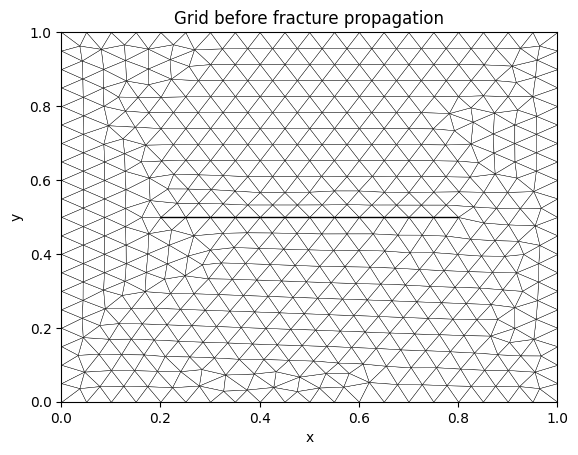

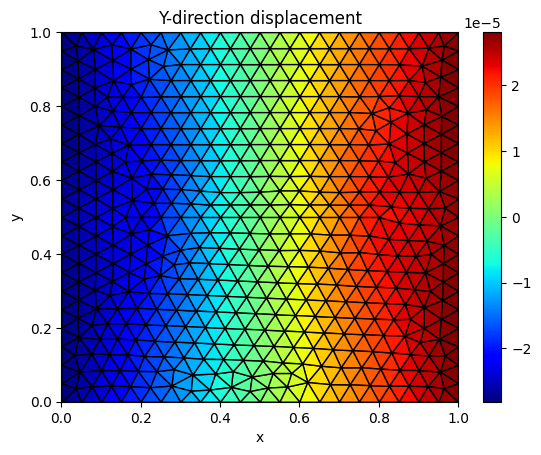

Grid Tensor grid in 1 dimensions.
Number of cells 12
Number of faces 13
Number of nodes 13
 has no 'u' defined in TIME_STEP_SOLUTIONS


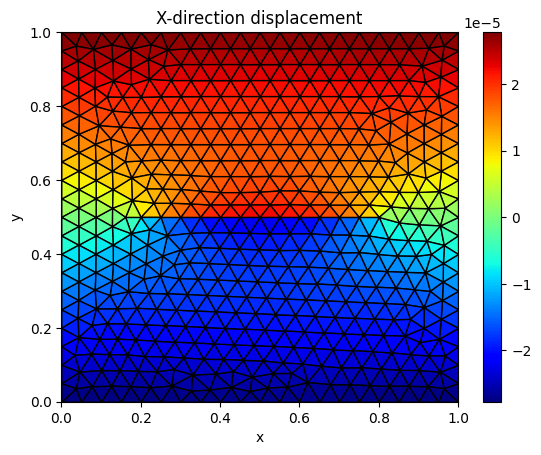

Grid Tensor grid in 1 dimensions.
Number of cells 12
Number of faces 13
Number of nodes 13
 has no 'u' defined in TIME_STEP_SOLUTIONS


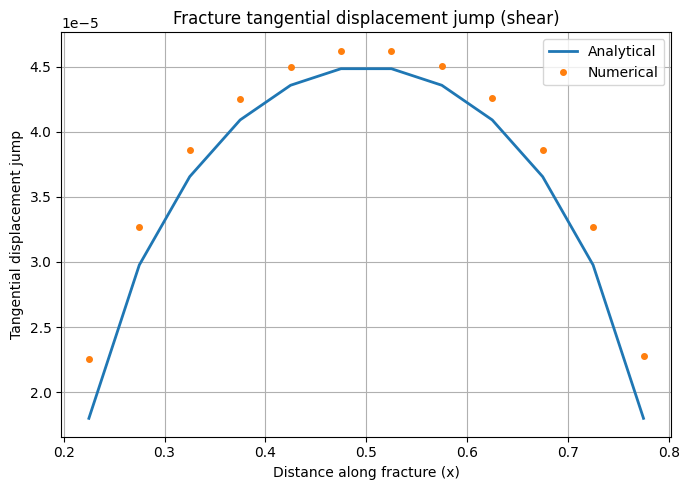

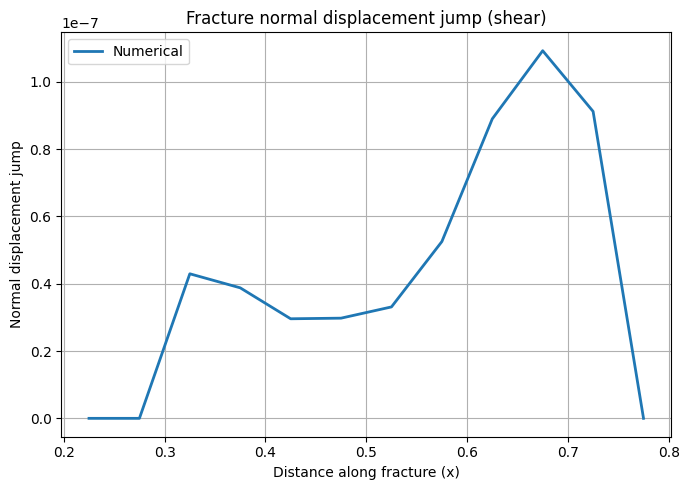

In [ ]:
from __future__ import annotations

import porepy as pp
import numpy as np

import math
import matplotlib.pyplot as plt
import scipy.sparse as sps

from westergaard2d import WestergaardShearMode2d

a = 0.3
poi = 0.25
shear_modulus = 1.0
lam = 2 * shear_modulus * poi / (1 - 2 * poi)

params = {
    "prepare_simulation": True,
    "material_constants": {"solid": pp.SolidConstants(shear_modulus=shear_modulus, lame_lambda=lam)},
    "a": a,
    "domain_size": 1.0,
    "meshing_arguments": {"cell_size": 0.05},
    "grid_type": "simplex",
    "theta_rad": math.radians(90 - 0),
    "num_bem_segments": 1000,
    "poi": poi,
    "error_exclusion_zone_fracture_tips": 0.0,
    "tau_inf": 1e-4,    # far_field shear stress
    "mu": 0.0,          # friction coefficient
    "p0": 0.0,          # This pressure value will not be calculated in this model. 
                        # But "p0" is needed because of model's parental class
}

model = WestergaardShearMode2d(params=params)
pp.run_time_dependent_model(model)

# Plot
pp.plot_grid(
    model.mdg,
    rgb=[1, 1, 1],
    figsize=(8,8), 
    plot_2d=True,           
    linewidth=0.3,
    alpha=1.0,
    title="Grid before fracture propagation"
)

# 2D displacement plot
for g, data in model.mdg.subdomains(return_data=True):
    # get 'u'（t=0 by default）
    u = data.get(pp.TIME_STEP_SOLUTIONS, {}).get("u", {}).get(0, None)
    
    if u is not None:
        # get the displacement y along the y direction
        y_disp = u[1::2]

        # plot
        pp.plot_grid(
            g,
            cell_value=y_disp,
            plot_2d=True,
            title="Y-direction displacement"
        )
    else:
        print(f"Grid {g} has no 'u' defined in TIME_STEP_SOLUTIONS")


# 2D displacement plot
for g, data in model.mdg.subdomains(return_data=True):
    # get 'u'（t=0 by default）
    u = data.get(pp.TIME_STEP_SOLUTIONS, {}).get("u", {}).get(0, None)
    
    if u is not None:
        # get the displacement x along the x direction
        x_disp = u[::2]

        # plot
        pp.plot_grid(
            g,
            cell_value=x_disp,
            plot_2d=True,
            title="X-direction displacement"
        )
    else:
        print(f"Grid {g} has no 'u' defined in TIME_STEP_SOLUTIONS")

# For displacement along the fracture
# Get the 1D fracture grid (assumes only one fracture)
fracture_grid = model.mdg.subdomains(dim=1)[0]
x_coords = fracture_grid.cell_centers[0]  # X coordinate of each fracture cell center

# Get numerical normal/tangential COD
u_jump = model.displacement_jump([fracture_grid])
u_jump_val = u_jump.value(model.equation_system)
normal_op = model.normal_component([fracture_grid])
u_cod_numerical = (normal_op @ u_jump).value(model.equation_system)
tangent_op = model.tangential_component([fracture_grid])
u_slip_numerical = (tangent_op @ u_jump).value(model.equation_system)
u_slip_analytical = model.exact_sol.exact_sol_tangential_fracture(model.mdg)

x_plot = x_coords

# Plot
plt.figure(figsize=(7, 5))
plt.plot(x_plot, u_slip_analytical, label="Analytical", lw=2)
plt.plot(x_plot, u_slip_numerical, 'o', label="Numerical", markersize=4)
plt.xlabel("Distance along fracture (x)")
plt.ylabel("Tangential displacement jump (y)")
plt.title("Fracture tangential displacement jump (shear)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(x_plot, u_cod_numerical, label="Numerical", lw=2)
plt.xlabel("Distance along fracture (x)")
plt.ylabel("Normal displacement jump (y)")
plt.title("Fracture normal displacement jump (shear)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
